<a href="https://colab.research.google.com/github/24pa1a4568-T3/EDA_Project/blob/main/EDA_Project_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df=pd.read_csv("/content/ecommerce_reviews_classification.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          251 non-null    object 
 1   rating_dup         256 non-null    float64
 2   user_id            252 non-null    float64
 3   sentiment          252 non-null    object 
 4   helpful_votes      248 non-null    float64
 5   rating             256 non-null    float64
 6   review_text        245 non-null    object 
 7   verified_purchase  246 non-null    object 
 8   product_id         253 non-null    float64
dtypes: float64(5), object(4)
memory usage: 18.8+ KB


In [5]:
df.select_dtypes(include=['number']).columns

Index(['rating_dup', 'user_id', 'helpful_votes', 'rating', 'product_id'], dtype='object')

In [6]:
for col in ['user_id', 'helpful_votes', 'rating', 'product_id']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, "Outliers:", len(outliers))

user_id Outliers: 0
helpful_votes Outliers: 0
rating Outliers: 0
product_id Outliers: 0


In [7]:
df.drop('rating_dup', axis=1, inplace=True)

In [8]:
df['review_id'].duplicated().sum()

np.int64(28)

In [9]:
df.drop_duplicates(subset=['review_id'], keep='first', inplace=True)

In [10]:
df[df.duplicated(keep=False)]

,review_id,user_id,sentiment,helpful_votes,rating,review_text,verified_purchase,product_id


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 237 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          236 non-null    object 
 1   user_id            225 non-null    float64
 2   sentiment          227 non-null    object 
 3   helpful_votes      221 non-null    float64
 4   rating             230 non-null    float64
 5   review_text        219 non-null    object 
 6   verified_purchase  221 non-null    object 
 7   product_id         228 non-null    float64
dtypes: float64(4), object(4)
memory usage: 16.7+ KB


In [12]:
df.isnull().sum()

,0
review_id,1
user_id,12
sentiment,10
helpful_votes,16
rating,7
review_text,18
verified_purchase,16
product_id,9


In [13]:
df['helpful_votes'].fillna(df['helpful_votes'].median())
df['rating'] = df['rating'].fillna(df['rating'].mode()[0])

In [14]:
df['review_text'] = df['review_text'].fillna('')

In [15]:
df['verified_purchase'].unique()

array(['No', 'Yes', nan, 'Ye', 'Ys', 'YES', 'es', 'NO', 'o', 'N'],
      dtype=object)

In [16]:
df['verified_purchase'] = (df['verified_purchase'].str.strip().str.lower().replace({'yes': 'Yes','y': 'Yes','no': 'No','n': 'No','ye':'Yes','ys':'Yes','es':'Yes','o':'No'}))

In [17]:
df['verified_purchase'].unique()

array(['No', 'Yes', nan], dtype=object)

In [18]:
df['verified_purchase'] = df['verified_purchase'].fillna(df['verified_purchase'].mode()[0])

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 237 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          236 non-null    object 
 1   user_id            225 non-null    float64
 2   sentiment          227 non-null    object 
 3   helpful_votes      221 non-null    float64
 4   rating             237 non-null    float64
 5   review_text        237 non-null    object 
 6   verified_purchase  237 non-null    object 
 7   product_id         228 non-null    float64
dtypes: float64(4), object(4)
memory usage: 16.7+ KB


In [20]:
df.isnull().sum()

,0
review_id,1
user_id,12
sentiment,10
helpful_votes,16
rating,0
review_text,0
verified_purchase,0
product_id,9


In [21]:
df = df[df['sentiment'].notna()]

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 227 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          226 non-null    object 
 1   user_id            216 non-null    float64
 2   sentiment          227 non-null    object 
 3   helpful_votes      211 non-null    float64
 4   rating             227 non-null    float64
 5   review_text        227 non-null    object 
 6   verified_purchase  227 non-null    object 
 7   product_id         218 non-null    float64
dtypes: float64(4), object(4)
memory usage: 16.0+ KB


In [24]:
df['review_id'] = ['R' + str(i) for i in np.arange(9000, 9000 + len(df))]

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 227 entries, 0 to 249
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          227 non-null    object 
 1   user_id            216 non-null    float64
 2   sentiment          227 non-null    object 
 3   helpful_votes      211 non-null    float64
 4   rating             227 non-null    float64
 5   review_text        227 non-null    object 
 6   verified_purchase  227 non-null    object 
 7   product_id         218 non-null    float64
dtypes: float64(4), object(4)
memory usage: 16.0+ KB


In [26]:
df.to_csv('preprocessed_ecommerce_reviews.csv', index=False)

In [27]:
df = pd.read_csv("/content/preprocessed_ecommerce_reviews.csv")

In [28]:
df.describe()

,user_id,helpful_votes,rating,product_id
count,216.000000,211.000000,227.000000,218.000000
mean,20254.615741,97.957346,3.687225,1048.912844
std,141.043637,57.501578,1.224371,28.480679
min,20002.000000,0.000000,1.000000,1000.000000
25%,20138.750000,53.000000,3.000000,1025.250000
50%,20265.500000,93.000000,4.000000,1049.000000
75%,20374.250000,147.000000,5.000000,1072.750000
max,20499.000000,199.000000,5.000000,1099.000000


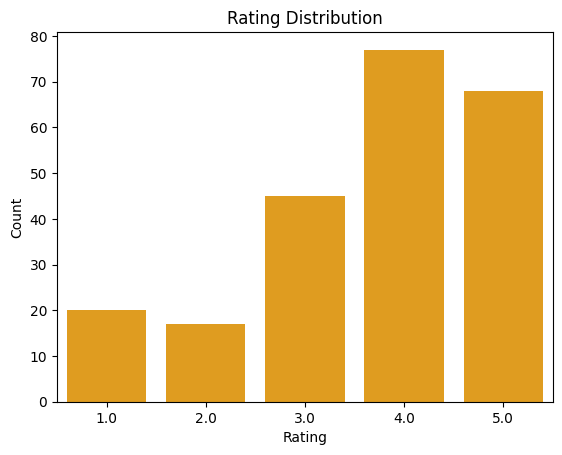

In [44]:
sns.countplot(data=df, x='rating',color="orange")
plt.title('Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

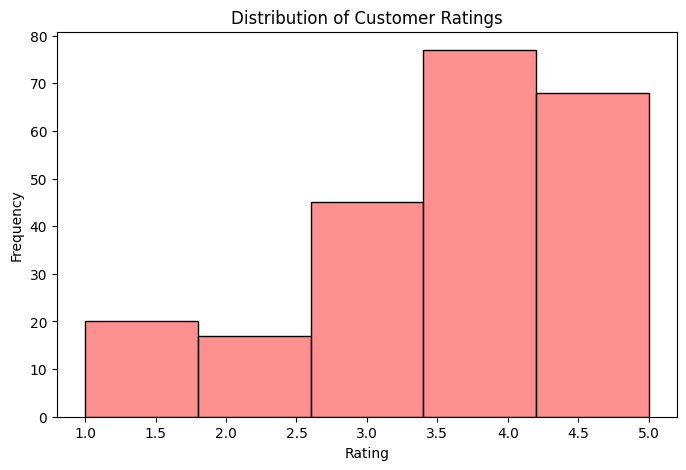

In [30]:
plt.figure(figsize=(8,5))
sns.histplot(data=df,x='rating',bins=5,color='#FF6B6B',edgecolor='black')
plt.title('Distribution of Customer Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

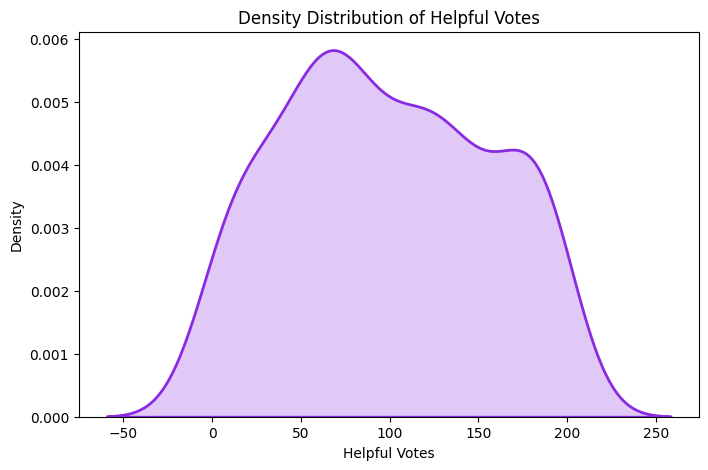

In [31]:
plt.figure(figsize=(8,5))
sns.kdeplot(data=df,x='helpful_votes',fill=True,color='#8A2BE2',linewidth=2)
plt.title('Density Distribution of Helpful Votes')
plt.xlabel('Helpful Votes')
plt.ylabel('Density')
plt.show()

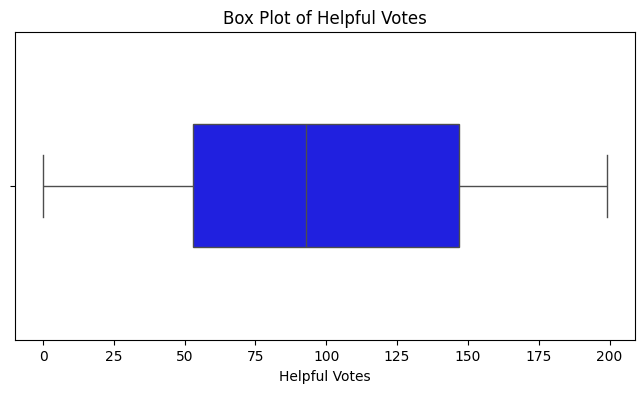

In [45]:
plt.figure(figsize=(8,4))
sns.boxplot(data=df,x='helpful_votes',color='blue',width=0.4)
plt.title('Box Plot of Helpful Votes')
plt.xlabel('Helpful Votes')
plt.show()

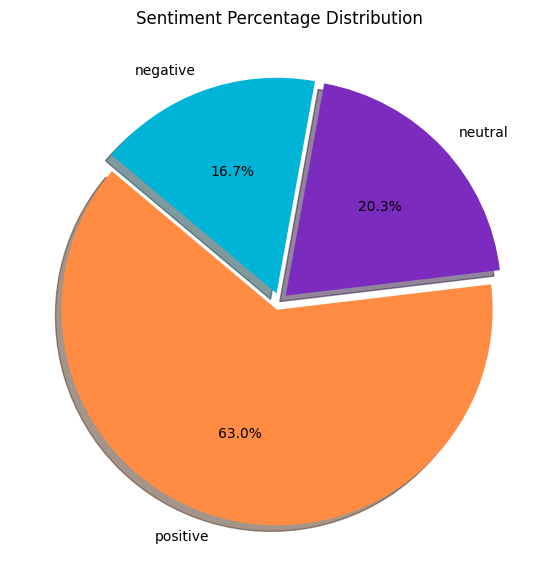

In [33]:
sentiment_counts = df['sentiment'].value_counts()
plt.figure(figsize=(7,7))
plt.pie(sentiment_counts,labels=sentiment_counts.index,autopct='%1.1f%%',startangle=140,colors=['#FF8C42', '#7B2CBF', '#00B4D8'],explode=[0.04] * len(sentiment_counts),shadow=True)
plt.title('Sentiment Percentage Distribution')
plt.show()

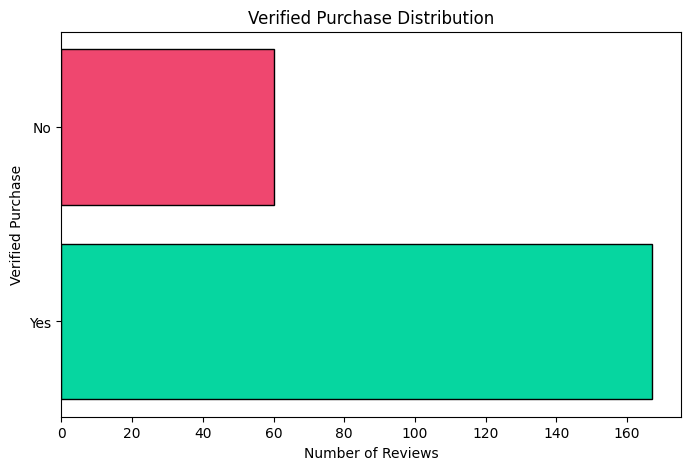

In [34]:
purchase_counts = df['verified_purchase'].value_counts()
plt.figure(figsize=(8,5))
plt.barh(purchase_counts.index,purchase_counts.values,color=['#06D6A0', '#EF476F'],edgecolor='black')
plt.title('Verified Purchase Distribution')
plt.xlabel('Number of Reviews')
plt.ylabel('Verified Purchase')
plt.show()

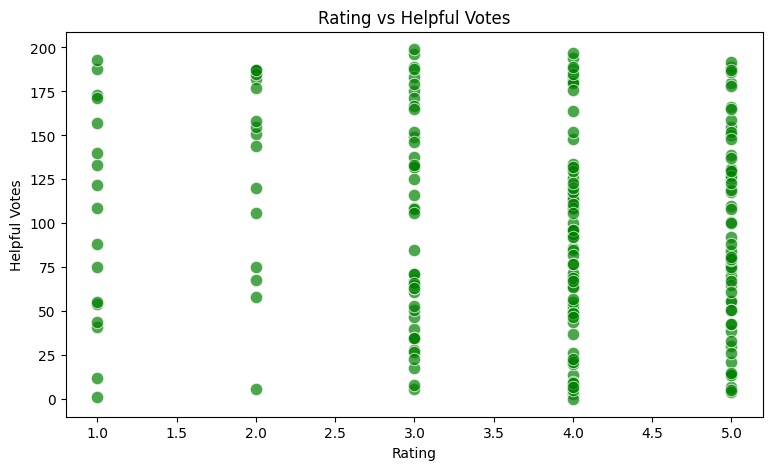

In [35]:
plt.figure(figsize=(9,5))
sns.scatterplot(data=df,x='rating',y='helpful_votes',color='green',s=80,alpha=0.7)
plt.title('Rating vs Helpful Votes')
plt.xlabel('Rating')
plt.ylabel('Helpful Votes')
plt.show()

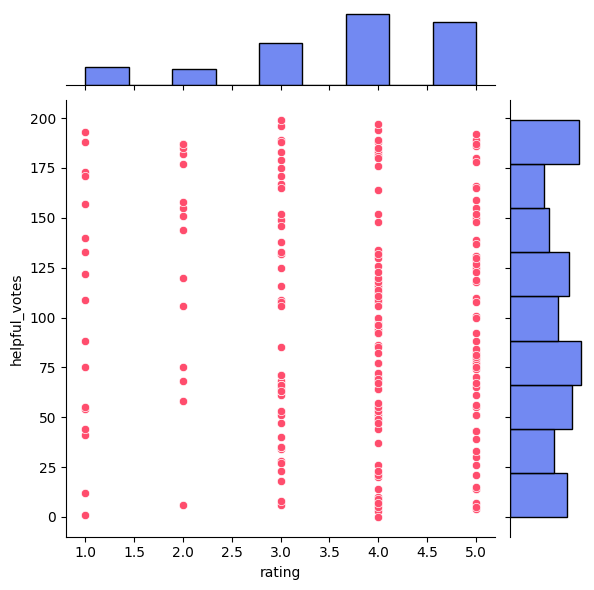

In [36]:
sns.jointplot(data=df,x='rating',y='helpful_votes',kind='scatter',color='#FF4D6D',marginal_kws={'color': '#4361EE'})
plt.show()

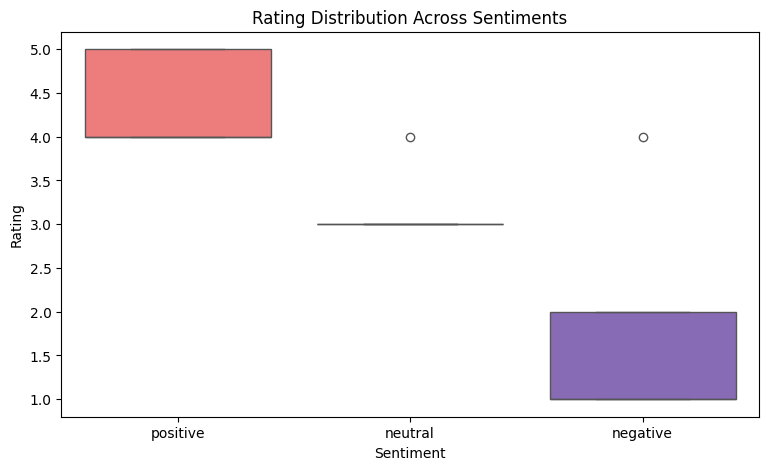

In [37]:
plt.figure(figsize=(9,5))
sns.boxplot(data=df,x='sentiment',y='rating',hue='sentiment',palette=['#FF6B6B', '#4ECDC4', '#845EC2'],legend=False)
plt.title('Rating Distribution Across Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Rating')
plt.show()

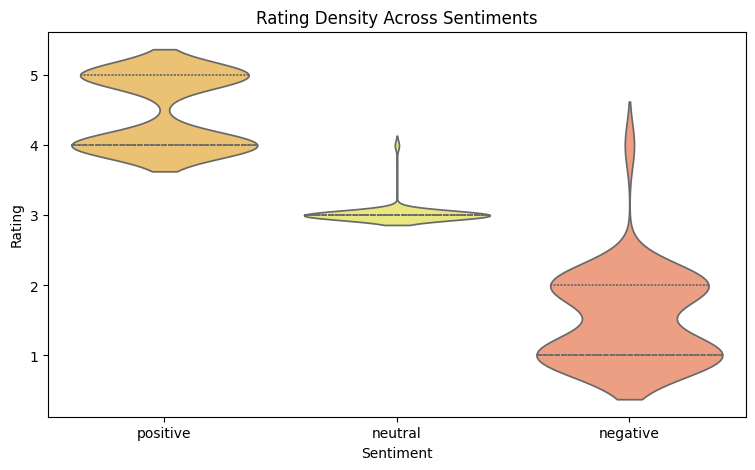

In [38]:
plt.figure(figsize=(9,5))
sns.violinplot(data=df,x='sentiment',y='rating',hue='sentiment',palette=['#FFC75F', '#F9F871', '#FF9671'],inner='quartile',legend=False)
plt.title('Rating Density Across Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Rating')
plt.show()

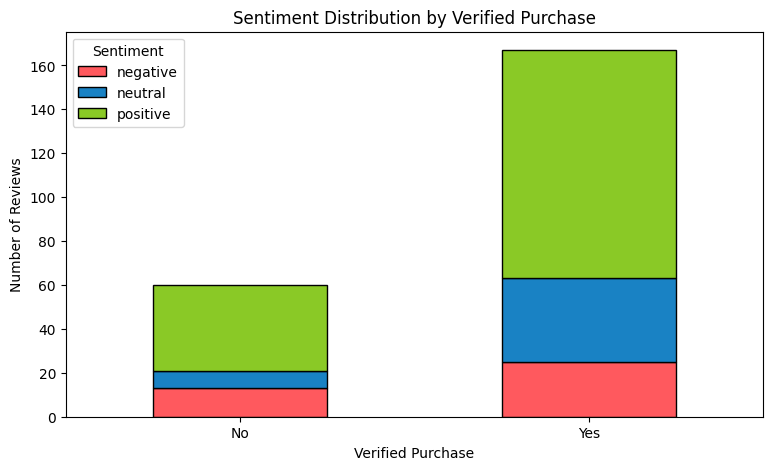

In [39]:
ct = pd.crosstab(df['verified_purchase'],df['sentiment'])
ct.plot(kind='bar',stacked=True,figsize=(9,5),color=['#FF595E', '#1982C4', '#8AC926'],edgecolor='black')
plt.title('Sentiment Distribution by Verified Purchase')
plt.xlabel('Verified Purchase')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.legend(title='Sentiment')
plt.show()

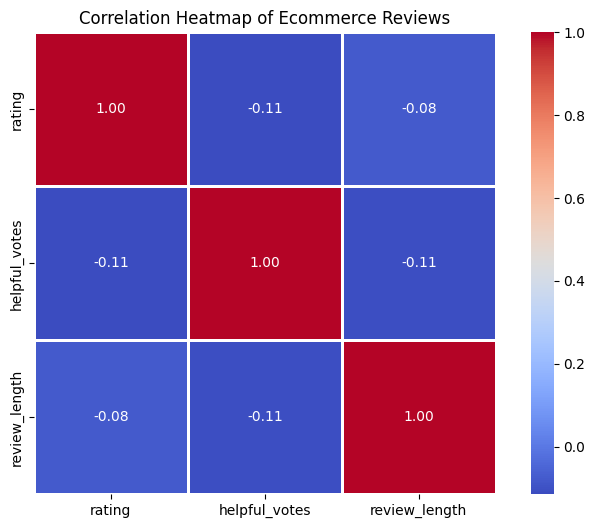

In [41]:
plt.figure(figsize=(9, 6))
# Calculate the review length column first
df['review_length'] = df['review_text'].fillna('').str.len()
corr = df[['rating', 'helpful_votes', 'review_length']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=2, fmt='.2f', square=True)
plt.title('Correlation Heatmap of Ecommerce Reviews')
plt.show()

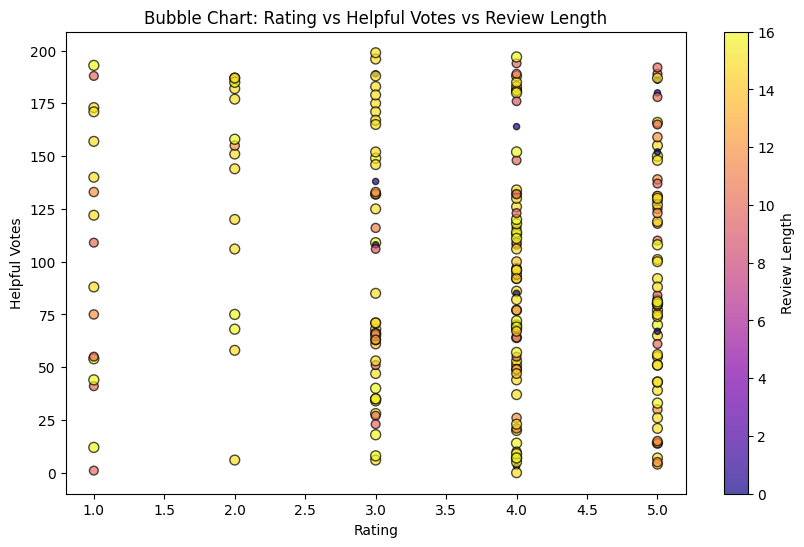

In [42]:
plt.figure(figsize=(10, 6))
plt.scatter(df['rating'],df['helpful_votes'],s=df['review_length'] * 2 + 20,c=df['review_length'],cmap='plasma',alpha=0.7,edgecolors='black')
plt.colorbar(label='Review Length')
plt.xlabel('Rating')
plt.ylabel('Helpful Votes')
plt.title('Bubble Chart: Rating vs Helpful Votes vs Review Length')
plt.show()

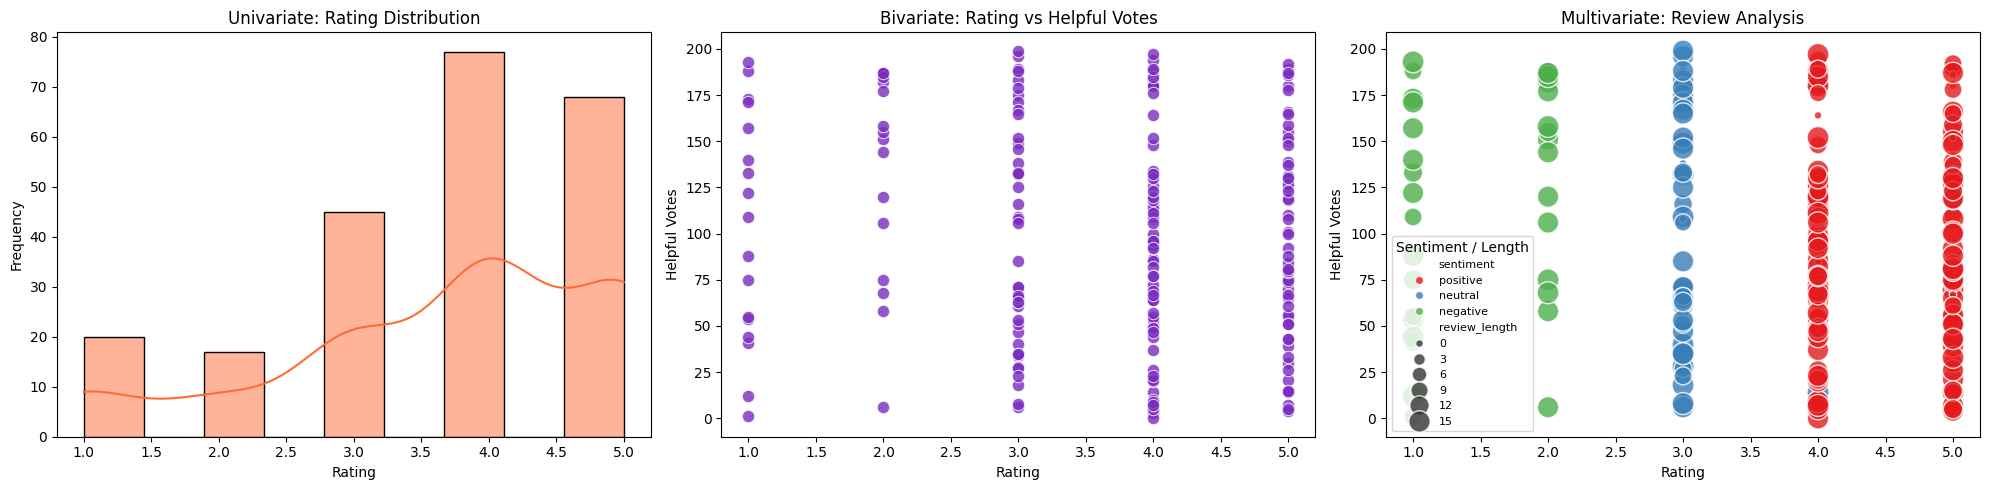

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
# 1. UNIVARIATE ANALYSIS
sns.histplot(data=df,x='rating',kde=True,color='#FF6B35',edgecolor='black',ax=axes[0])
axes[0].set_title('Univariate: Rating Distribution')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Frequency')
# 2. BIVARIATE ANALYSIS
sns.scatterplot(data=df,x='rating',y='helpful_votes',color='#7B2CBF',s=80,alpha=0.8,ax=axes[1])
axes[1].set_title('Bivariate: Rating vs Helpful Votes')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Helpful Votes')
# 3. MULTIVARIATE ANALYSIS
sns.scatterplot(data=df,x='rating',y='helpful_votes',hue='sentiment',size='review_length',sizes=(30, 250),palette='Set1',alpha=0.8,ax=axes[2])
axes[2].set_title('Multivariate: Review Analysis')
axes[2].set_xlabel('Rating')
axes[2].set_ylabel('Helpful Votes')
axes[2].legend(fontsize=8, title='Sentiment / Length')
plt.tight_layout()
plt.show()

# **Complete Report**
The Exploratory Data Analysis (EDA) was performed on the preprocessed ecommerce reviews dataset using univariate, bivariate, and multivariate analysis. Various visualizations were used to understand rating distributions, customer sentiment, review patterns, and helpful votes. The analysis also explored relationships between ratings, review length, sentiment, and verified purchases. These visualizations helped identify important patterns and understand customer feedback more effectively.

